**Lab 3: Supervised Learning**

**Breast Cancer Diagnosis Using Supervised Machine Learning: A Comparative Study of Classification Models**

Research question: How accurately can supervised learning models distinguish malignant from benign breast tumours using cell nucleus characteristics?

In [142]:
#%pip install ucimlrepo  #just running this once

Necessary libraries:

In [143]:
# Data handling and numerical operations
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt

# Data splitting, cross-validation and hyperparameter tuning
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
)

# Preprocessing within a modelling pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Baseline and classification models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Classification evaluation
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay,
)

# Feature interpretation
from sklearn.inspection import permutation_importance

Dataset loading:

In [144]:

from ucimlrepo import fetch_ucirepo

# Download the dataset from UCI
breast_cancer = fetch_ucirepo(id=17)

# Extract predictors and the original diagnosis labels
X = breast_cancer.data.features.copy()
y_original = breast_cancer.data.targets["Diagnosis"].copy()

# Check labels before encoding
assert y_original.isin(["M", "B"]).all(), "Unexpected or missing diagnosis labels."

# Encode malignant as 1 and benign as 0
y = y_original.map({"M": 1, "B": 0}).astype(int)

# Inspect dimensions, feature names and data types
print("X dimensions:", X.shape)
print("y dimensions:", y.shape)

print("\nFeature names:")
print(X.columns.tolist())

print("\nFeature data types:")
print(X.dtypes)

print("\nOriginal labels:", sorted(y_original.unique()))
print("Encoded labels:", sorted(y.unique()))
print("Target data type:", y.dtype)

print("\nClass counts (0 = benign, 1 = malignant):")
print(y.value_counts().sort_index())

X dimensions: (569, 30)
y dimensions: (569,)

Feature names:
['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3']

Feature data types:
radius1               float64
texture1              float64
perimeter1            float64
area1                 float64
smoothness1           float64
compactness1          float64
concavity1            float64
concave_points1       float64
symmetry1             float64
fractal_dimension1    float64
radius2               float64
texture2              float64
perimeter2            float64
area2                 float64
smoothness2           float64
compactness2          float64
co

In [145]:
# Verify dimensions and row alignment
assert X.shape == (569, 30), "Unexpected feature dimensions."
assert y.shape == (569,), "Unexpected target dimensions."
assert X.index.equals(y.index), "Features and target are misaligned."

# Verify numeric predictors, missing values and encoded labels
assert X.select_dtypes(include="number").shape[1] == 30, "Non-numeric predictors found."
assert not X.isna().any().any(), "Missing feature values found."
assert not y.isna().any(), "Missing target values found."
assert set(y.unique()) == {0, 1}, "Unexpected encoded labels."

# Ensure identifiers and the target are excluded from predictors
assert "ID" not in X.columns, "ID must not be a predictor."
assert "Diagnosis" not in X.columns, "Target leakage detected."

print("All dataset-loading checks passed.")

All dataset-loading checks passed.


**Data quality assessment:**

Check missing values, types, constants and invalid measurements

In [146]:
numeric_X = X.select_dtypes(include="number")

quality_summary = pd.DataFrame({
    "dtype": X.dtypes.astype(str),
    "missing": X.isna().sum(),
    "unique_nonmissing": X.nunique(dropna=True),
    "infinite": np.isinf(numeric_X).sum(),
    "negative": numeric_X.lt(0).sum(),
})

# Check zero values only where a positive measurement is expected
size_columns = [
    column
    for column in [
        "radius1", "perimeter1", "area1",
        "radius3", "perimeter3", "area3",
    ]
    if column in numeric_X.columns
]

quality_summary["zero_size"] = 0
quality_summary.loc[size_columns, "zero_size"] = (
    numeric_X[size_columns].eq(0).sum()
)

non_numeric_columns = X.columns.difference(numeric_X.columns).tolist()
constant_columns = quality_summary.index[
    quality_summary["unique_nonmissing"] <= 1
].tolist()

display(quality_summary)

print("Non-numeric columns:", non_numeric_columns)
print("Constant or entirely missing columns:", constant_columns)
print("Target dtype:", y.dtype)
print("Missing target values:", y.isna().sum())
print("Unexpected target values:", y.loc[~y.isin([0, 1])].unique())

,dtype,missing,unique_nonmissing,infinite,negative,zero_size
radius1,float64,0,456,0,0,0
texture1,float64,0,479,0,0,0
perimeter1,float64,0,522,0,0,0
area1,float64,0,539,0,0,0
smoothness1,float64,0,474,0,0,0
compactness1,float64,0,537,0,0,0
concavity1,float64,0,537,0,0,0
concave_points1,float64,0,542,0,0,0
symmetry1,float64,0,432,0,0,0
fractal_dimension1,float64,0,499,0,0,0


Non-numeric columns: []
Constant or entirely missing columns: []
Target dtype: int64
Missing target values: 0
Unexpected target values: []


Check and investigate repetitions:

In [147]:
assert X.index.equals(y.index), "Features and target are misaligned."

observations = X.assign(diagnosis=y)

repeated_features = X.duplicated(keep=False)
duplicate_observations = observations.duplicated()

print("Rows involved in repeated feature profiles:",
      repeated_features.sum())
print("Duplicate observations beyond the first occurrence:",
      duplicate_observations.sum())

# Inspect identical predictors and check for conflicting diagnoses
if repeated_features.any():
    repeated_rows = observations.loc[repeated_features]
    display(repeated_rows.sort_values(X.columns.tolist()))

    diagnoses_per_profile = repeated_rows.groupby(
        X.columns.tolist(), dropna=False
    )["diagnosis"].nunique(dropna=False)

    print("Repeated feature profiles with conflicting diagnoses:",
          diagnoses_per_profile.gt(1).sum())

# Inspect repeated identifiers without adding IDs to the predictors
ids = breast_cancer.data.ids
assert ids.index.equals(X.index), "Identifiers are misaligned."

repeated_ids = ids.duplicated(keep=False)
print("Rows involved in repeated IDs:", repeated_ids.sum())

if repeated_ids.any():
    display(
        pd.concat([ids, observations], axis=1).loc[repeated_ids]
    )

Rows involved in repeated feature profiles: 0
Duplicate observations beyond the first occurrence: 0
Rows involved in repeated IDs: 0


Calculate descriptive statistics:

In [148]:
descriptive_statistics = numeric_X.describe().T
display(descriptive_statistics)

,count,mean,std,min,25%,50%,75%,max
radius1,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture1,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter1,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area1,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness1,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness1,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity1,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_points1,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry1,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension1,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


Record assessment and verify consistency:

In [149]:
missing_predictors = quality_summary["missing"].sum() > 0

invalid_measurements = quality_summary[
    ["infinite", "negative", "zero_size"]
].gt(0).any().any()

cleaning_review_needed = (
    bool(non_numeric_columns)
    or bool(constant_columns)
    or repeated_features.any()
    or repeated_ids.any()
    or invalid_measurements
    or not y.isin([0, 1]).all()
)

quality_decisions = pd.Series({
    "Imputation": (
        "Missing predictors detected; decide treatment using training data."
        if missing_predictors
        else "Not required: no missing predictor values."
    ),
    "Other cleaning": (
        "Review flagged issues before deciding whether changes are needed."
        if cleaning_review_needed
        else "No other cleaning indicated by these checks."
    ),
}, name="assessment")

display(quality_decisions.to_frame())

# Verify assessment consistency
assert X.shape == (569, 30)
assert y.shape == (569,)
assert descriptive_statistics["count"].eq(numeric_X.count()).all()

print("Assessment completed. Review the findings above.")

,assessment
Imputation,Not required: no missing predictor values.
Other cleaning,No other cleaning indicated by these checks.


Assessment completed. Review the findings above.


**Exploratory data analysis**

,count,percentage
Diagnosis,,
Benign,357,62.7
Malignant,212,37.3


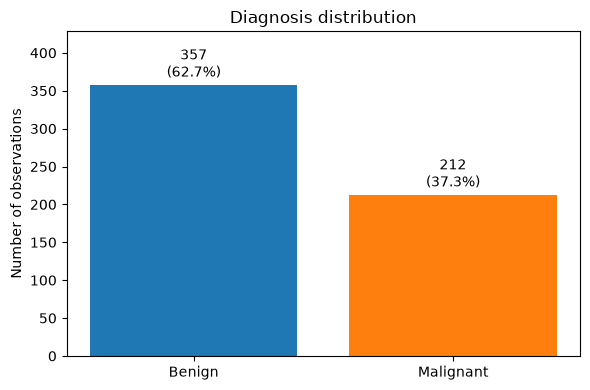

Majority-to-minority ratio: 1.68:1


In [150]:
#Plot the class distribution and calculate its proportions

assert X.index.equals(y.index), "Features and target are misaligned."
assert set(y.unique()) == {0, 1}, "Check the target encoding."

class_names = ["Benign", "Malignant"]
class_colors = ["tab:blue", "tab:orange"]

class_counts = y.value_counts().reindex([0, 1])
class_percentages = 100 * class_counts / len(y)

class_summary = pd.DataFrame({
    "count": class_counts,
    "percentage": class_percentages,
}).rename(index={0: "Benign", 1: "Malignant"})

display(class_summary.round(1))

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(class_names, class_counts, color=class_colors)
ax.bar_label(
    bars,
    labels=[
        f"{count}\n({percentage:.1f}%)"
        for count, percentage in zip(class_counts, class_percentages)
    ],
    padding=3,
)

ax.set_ylim(0, class_counts.max() * 1.2)
ax.set_title("Diagnosis distribution")
ax.set_ylabel("Number of observations")

plt.tight_layout()
plt.show()

print(
    "Majority-to-minority ratio:",
    f"{class_counts.max() / class_counts.min():.2f}:1"
)

Inspect the overall distributions of mean radius, texture, smoothness and concavity:

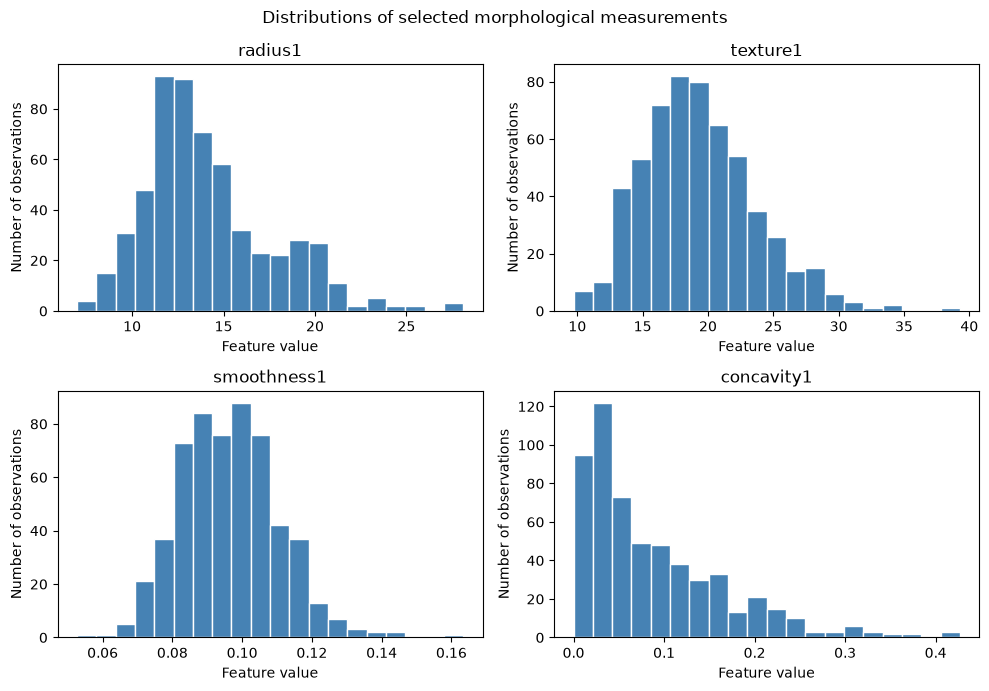

In [151]:
eda_features = ["radius1", "texture1", "smoothness1", "concavity1"]

assert set(eda_features).issubset(X.columns), "Check UCI feature names."
assert X[eda_features].notna().all().all(), "Review missing values first."

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, feature in zip(axes.flat, eda_features):
    ax.hist(
        X[feature],
        bins=20,
        color="steelblue",
        edgecolor="white",
    )
    ax.set_title(feature)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Number of observations")

fig.suptitle("Distributions of selected morphological measurements")
plt.tight_layout()
plt.show()

Compare the same measurements across classes using boxplots:

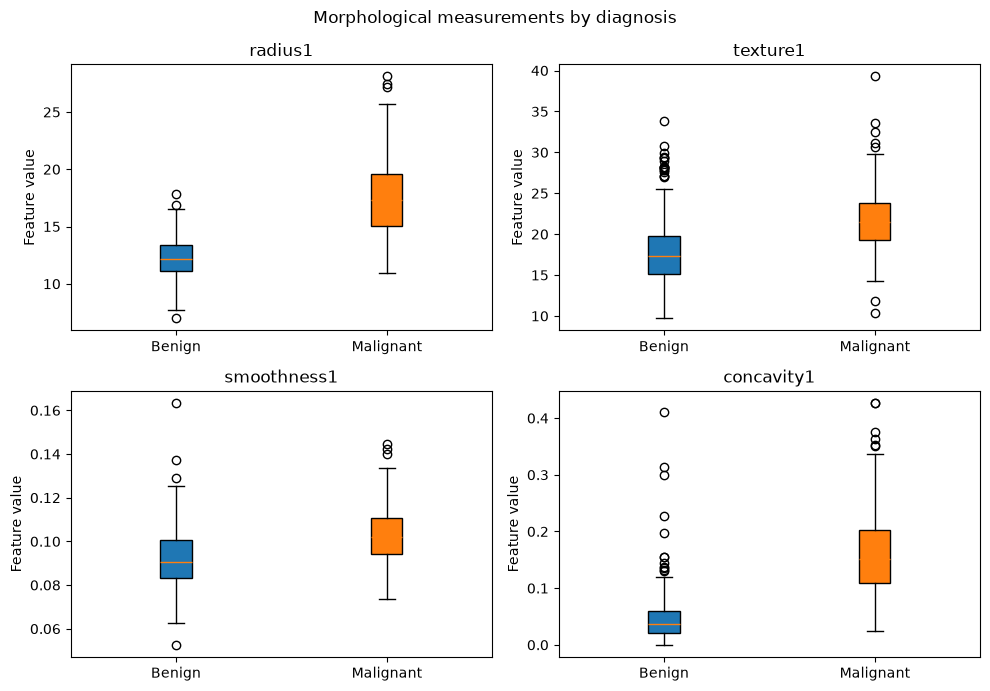

,radius1,texture1,smoothness1,concavity1
Diagnosis,,,,
Benign,12.200,17.39,0.091,0.037
Malignant,17.325,21.46,0.102,0.151


In [152]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, feature in zip(axes.flat, eda_features):
    values_by_class = [
        X.loc[y == 0, feature],
        X.loc[y == 1, feature],
    ]

    boxes = ax.boxplot(values_by_class, patch_artist=True)

    for box, color in zip(boxes["boxes"], class_colors):
        box.set_facecolor(color)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(class_names)
    ax.set_title(feature)
    ax.set_ylabel("Feature value")

fig.suptitle("Morphological measurements by diagnosis")
plt.tight_layout()
plt.show()

# Numerical support for describing the class differences
medians_by_class = X[eda_features].groupby(y).median()
medians_by_class.index = medians_by_class.index.map({
    0: "Benign",
    1: "Malignant",
})

display(medians_by_class.round(3))

Create the correlation heatmap using all predictors, excluding the diagnosis:

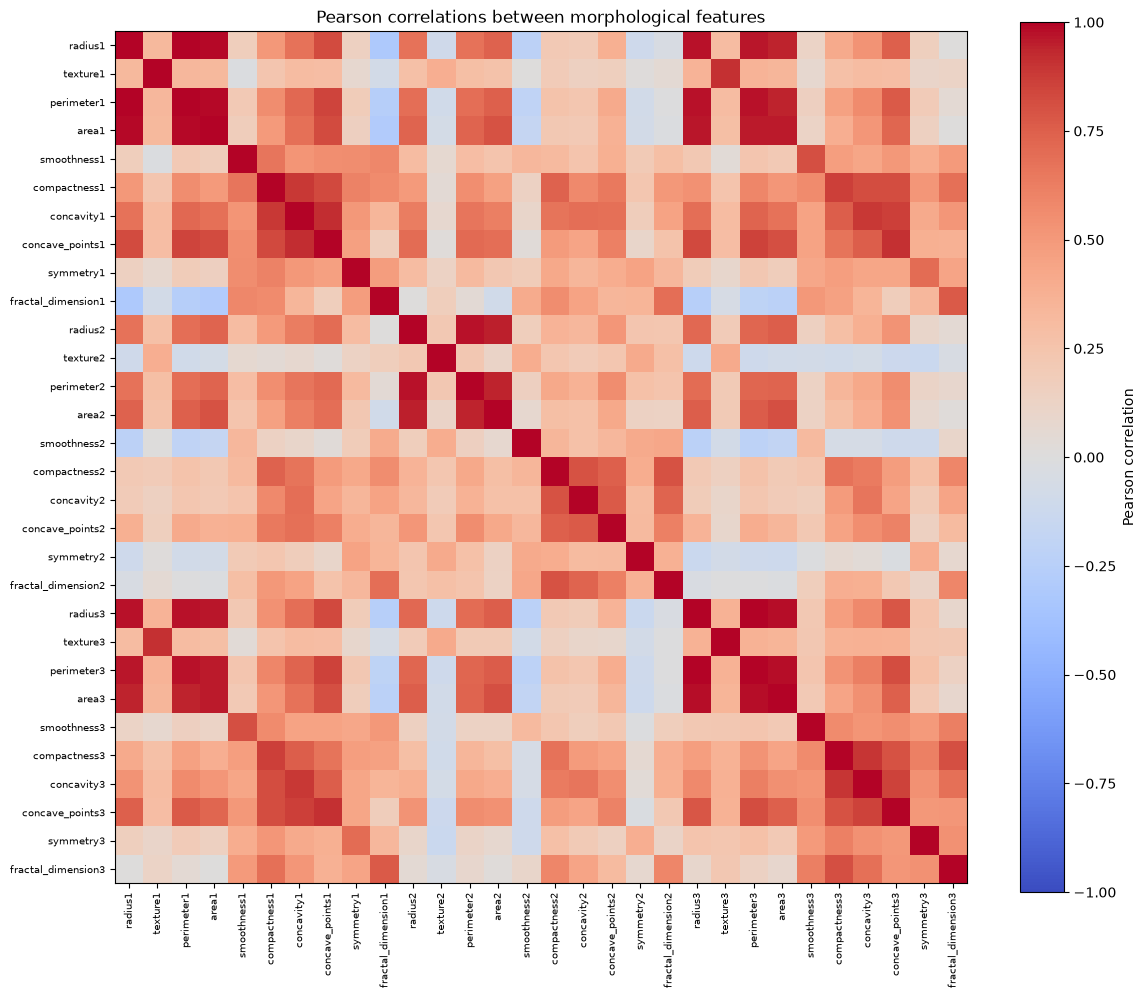

,,Pearson r
feature_1,feature_2,
radius1,perimeter1,0.998
radius3,perimeter3,0.994
radius1,area1,0.987
perimeter1,area1,0.987
radius3,area3,0.984
perimeter3,area3,0.978
radius2,perimeter2,0.973
perimeter1,perimeter3,0.970
radius1,radius3,0.970


Pairs with |r| >= 0.90: 21


In [153]:
correlation_matrix = X.corr(method="pearson")

fig, ax = plt.subplots(figsize=(12, 10))

heatmap = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    interpolation="nearest",
)

positions = np.arange(X.shape[1])

ax.set_xticks(positions)
ax.set_yticks(positions)
ax.set_xticklabels(X.columns, rotation=90, fontsize=7)
ax.set_yticklabels(X.columns, fontsize=7)

ax.set_title("Pearson correlations between morphological features")
fig.colorbar(heatmap, ax=ax, label="Pearson correlation")

plt.tight_layout()
plt.show()

# Inspect each pair once, excluding self-correlations
upper_triangle = np.triu(
    np.ones(correlation_matrix.shape, dtype=bool),
    k=1,
)

correlation_pairs = correlation_matrix.where(upper_triangle).stack()

# Exploratory flag only: this threshold does not select features
high_correlation_pairs = correlation_pairs[
    correlation_pairs.abs() >= 0.90
].sort_values(
    key=lambda values: values.abs(),
    ascending=False,
)

high_correlation_pairs.index.names = ["feature_1", "feature_2"]

display(high_correlation_pairs.to_frame("Pearson r").round(3))
print("Pairs with |r| >= 0.90:", len(high_correlation_pairs))

Verify that the summaries are consistent:

In [154]:
assert class_counts.sum() == len(y)
assert X.shape == (569, 30), "The original predictors should remain intact."

assert correlation_matrix.shape == (30, 30)
assert np.isfinite(correlation_matrix.to_numpy()).all(), (
    "Review missing values or constant columns."
)
assert np.allclose(correlation_matrix, correlation_matrix.T)
assert np.allclose(np.diag(correlation_matrix), 1)

print("EDA verification checks passed.")

EDA verification checks passed.


**Train/Test split**


Create the fixed split:

In [155]:
# Preserve original indices so observations remain traceable
assert X.index.is_unique, "Original row indices must be unique."
assert X.index.equals(y.index), "Features and target are misaligned."
assert set(y.unique()) == {0, 1}, "Check the target encoding."

record_ids = breast_cancer.data.ids["ID"]

assert record_ids.index.equals(X.index), "Record IDs are misaligned."
assert record_ids.notna().all(), "Some record IDs are missing."

# Create the 80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (455, 30)
X_test:  (114, 30)
y_train: (455,)
y_test:  (114,)


Compare class counts and percentages:

In [156]:
split_counts = pd.DataFrame({
    "Full": y.value_counts(),
    "Train": y_train.value_counts(),
    "Test": y_test.value_counts(),
}).reindex([0, 1])

split_counts.index = ["Benign (0)", "Malignant (1)"]

split_percentages = (
    split_counts.div(split_counts.sum(axis=0), axis="columns") * 100
)

print("Class counts:")
display(split_counts)

print("Class percentages:")
display(split_percentages.round(2))

# Allow differences corresponding to at most one observation per partition
for partition, labels in [("Train", y_train), ("Test", y_test)]:
    largest_difference = (
        split_percentages[partition] - split_percentages["Full"]
    ).abs().max()

    assert largest_difference <= 100 / len(labels), (
        f"Unexpected class proportions in {partition}."
    )

Class counts:


,Full,Train,Test
Benign (0),357,285,72
Malignant (1),212,170,42


Class percentages:


,Full,Train,Test
Benign (0),62.74,62.64,63.16
Malignant (1),37.26,37.36,36.84


Check row separation, recorded identifiers and identical feature profiles.

In [157]:
# Verify alignment and complete partition sizes
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert len(X_train) + len(X_test) == len(X)

# Check whether original row indices overlap
shared_indices = X_train.index.intersection(X_test.index)

# Check whether recorded identifiers overlap
train_ids = set(record_ids.loc[X_train.index])
test_ids = set(record_ids.loc[X_test.index])
shared_ids = train_ids.intersection(test_ids)

# Check for identical complete feature profiles across partitions
shared_profiles = X_train.merge(
    X_test,
    on=X.columns.tolist(),
    how="inner",
)

print("Shared original row indices:", len(shared_indices))
print("Shared UCI IDs:", len(shared_ids))
print("Identical feature profiles across partitions:", len(shared_profiles))

assert shared_indices.empty, "The same original row occurs in both partitions."
assert not shared_ids, "Recorded IDs overlap; investigate grouping."
assert shared_profiles.empty, (
    "Identical feature profiles occur across partitions; investigate."
)

print("Partition integrity checks passed.")

Shared original row indices: 0
Shared UCI IDs: 0
Identical feature profiles across partitions: 0
Partition integrity checks passed.


**Preprocessing**

Decide whether imputation is needed using X_train only

In [158]:
from sklearn.impute import SimpleImputer

missing_train = X_train.isna().sum()
imputation_required = bool(missing_train.gt(0).any())

display(missing_train.to_frame("missing_training_values"))
print("Imputation required:", imputation_required)

,missing_training_values
radius1,0
texture1,0
perimeter1,0
area1,0
smoothness1,0
compactness1,0
concavity1,0
concave_points1,0
symmetry1,0
fractal_dimension1,0


Imputation required: False


Construct complete model pipelines:

In [159]:
def make_model_pipeline(classifier, scale_features):
    steps = []

    if imputation_required:
        steps.append(("imputer", SimpleImputer(strategy="median")))

    if scale_features:
        steps.append(("scaler", StandardScaler()))

    steps.append(("classifier", classifier))

    return Pipeline(steps)


model_pipelines = {
    "Logistic regression": make_model_pipeline(
        LogisticRegression(max_iter=2000),
        scale_features=True,
    ),
    "KNN": make_model_pipeline(
        KNeighborsClassifier(),
        scale_features=True,
    ),
    "SVM": make_model_pipeline(
        SVC(),
        scale_features=True,
    ),
    "Random forest": make_model_pipeline(
        RandomForestClassifier(random_state=42),
        scale_features=False,
    ),
}

Verify the configurations and confirm that preprocessing has not been fitted prematurely:

In [160]:
for name, pipeline in model_pipelines.items():
    print(f"{name}: {' -> '.join(pipeline.named_steps)}")

    if "imputer" in pipeline.named_steps:
        assert not hasattr(
            pipeline.named_steps["imputer"], "statistics_"
        ), "The imputer has already been fitted."

    if "scaler" in pipeline.named_steps:
        assert not hasattr(
            pipeline.named_steps["scaler"], "mean_"
        ), "The scaler has already been fitted."

assert X_train.shape == (455, 30)
assert X_train.index.equals(y_train.index)

print("Pipeline configuration checks passed.")

Logistic regression: scaler -> classifier
KNN: scaler -> classifier
SVM: scaler -> classifier
Random forest: classifier
Pipeline configuration checks passed.


**Baseline model**

Define the baseline, five reproducible stratified folds and the scoring metrics.

In [161]:
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score,
)

baseline_model = DummyClassifier(strategy="most_frequent")

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

# Malignant = 1 is the positive class
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label=1, zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),
    "f1": make_scorer(
        f1_score, pos_label=1, zero_division=0
    ),
    "roc_auc": "roc_auc",
}

assert set(y_train.unique()) == {0, 1}
assert y_train.value_counts().min() >= cv.n_splits

Run cross-validation:

In [162]:
baseline_cv_results = cross_validate(
    estimator=baseline_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    error_score="raise",
)

Record individual fold scores and their mean and standard deviation for later comparison:

In [163]:
baseline_fold_scores = pd.DataFrame(
    {
        metric: baseline_cv_results[f"test_{metric}"]
        for metric in scoring
    },
    index=pd.RangeIndex(1, cv.n_splits + 1, name="fold"),
)

baseline_summary = pd.DataFrame({
    "mean": baseline_fold_scores.mean(),
    "std": baseline_fold_scores.std(ddof=1),
})
baseline_summary.index.name = "metric"

print("Baseline scores by validation fold:")
display(baseline_fold_scores.round(4))

print("Baseline cross-validation summary:")
display(baseline_summary.round(4))

Baseline scores by validation fold:


,accuracy,precision,recall,f1,roc_auc
fold,,,,,
1,0.6264,0.0,0.0,0.0,0.5
2,0.6264,0.0,0.0,0.0,0.5
3,0.6264,0.0,0.0,0.0,0.5
4,0.6264,0.0,0.0,0.0,0.5
5,0.6264,0.0,0.0,0.0,0.5


Baseline cross-validation summary:


,mean,std
metric,,
accuracy,0.6264,0.0
precision,0.0000,0.0
recall,0.0000,0.0
f1,0.0000,0.0
roc_auc,0.5000,0.0


Check the results against that expected behaviour:

In [164]:
assert baseline_fold_scores.shape == (5, len(scoring))
assert np.isfinite(baseline_fold_scores.to_numpy()).all()

# The expected majority class in this training partition is benign
assert y_train.value_counts().idxmax() == 0

assert np.isclose(
    baseline_fold_scores["accuracy"].mean(),
    y_train.eq(0).mean(),
)

assert np.allclose(
    baseline_fold_scores[["precision", "recall", "f1"]],
    0,
)

assert np.allclose(baseline_fold_scores["roc_auc"], 0.5)

print("Baseline verification checks passed.")

Baseline verification checks passed.


**Compare classification models**

Update model_pipelines with the six requested models:

In [165]:
from sklearn.tree import DecisionTreeClassifier

model_pipelines = {
    "Logistic regression": make_model_pipeline(
        LogisticRegression(
            solver="lbfgs",
            C=1.0,
            max_iter=2000,
        ),
        scale_features=True,
    ),
    "SVM (linear)": make_model_pipeline(
        SVC(kernel="linear", C=1.0),
        scale_features=True,
    ),
    "SVM (RBF)": make_model_pipeline(
        SVC(kernel="rbf", C=1.0, gamma="scale"),
        scale_features=True,
    ),
    "KNN": make_model_pipeline(
        KNeighborsClassifier(n_neighbors=5),
        scale_features=True,
    ),
    "Decision tree": make_model_pipeline(
        DecisionTreeClassifier(random_state=42),
        scale_features=False,
    ),
    "Random forest": make_model_pipeline(
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
        ),
        scale_features=False,
    ),
}

Freeze the cross-validation partitions once, then supply that exact list to every model:

In [166]:
cv_splits = list(cv.split(X_train, y_train))

assert len(cv_splits) == 5

for fit_positions, valid_positions in cv_splits:
    assert np.intersect1d(
        fit_positions, valid_positions
    ).size == 0

# Every training observation must be validated exactly once
validation_positions = np.concatenate([
    valid_positions
    for _, valid_positions in cv_splits
])

assert np.array_equal(
    np.sort(validation_positions),
    np.arange(len(X_train)),
)

Fit and evaluate each model within those folds:

In [167]:
comparison_models = {
    "Dummy (majority)": baseline_model,
    **model_pipelines,
}

model_cv_results = {}
model_fold_scores = {}

for name, model in comparison_models.items():
    print(f"Evaluating {name}...")

    results = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv_splits,
        scoring=scoring,
        error_score="raise",
    )

    model_cv_results[name] = results

    model_fold_scores[name] = pd.DataFrame(
        {
            metric: results[f"test_{metric}"]
            for metric in scoring
        },
        index=pd.RangeIndex(1, len(cv_splits) + 1, name="fold"),
    )

Evaluating Dummy (majority)...
Evaluating Logistic regression...
Evaluating SVM (linear)...
Evaluating SVM (RBF)...
Evaluating KNN...
Evaluating Decision tree...
Evaluating Random forest...


Record individual fold scores and a comparison table containing the mean and sample standard deviation of every metric:

In [168]:
all_fold_scores = pd.concat(
    model_fold_scores,
    names=["model", "fold"],
)

comparison_summary = pd.DataFrame({
    name: fold_scores.agg(["mean", "std"]).unstack()
    for name, fold_scores in model_fold_scores.items()
}).T

comparison_summary.index.name = "model"
comparison_summary.columns.names = ["metric", "statistic"]

print("Individual validation-fold scores:")
display(all_fold_scores.round(4))

print("Cross-validation means and standard deviations:")
display(comparison_summary.round(4))

Individual validation-fold scores:


accuracy  precision  recall      f1  roc_auc
model               fold                                              
Dummy (majority)    1       0.6264     0.0000  0.0000  0.0000   0.5000
                    2       0.6264     0.0000  0.0000  0.0000   0.5000
                    3       0.6264     0.0000  0.0000  0.0000   0.5000
                    4       0.6264     0.0000  0.0000  0.0000   0.5000
                    5       0.6264     0.0000  0.0000  0.0000   0.5000
Logistic regression 1       0.9560     1.0000  0.8824  0.9375   0.9948
                    2       0.9670     0.9429  0.9706  0.9565   0.9990
                    3       1.0000     1.0000  1.0000  1.0000   1.0000
                    4       0.9780     1.0000  0.9412  0.9697   0.9871
                    5       0.9670     0.9429  0.9706  0.9565   0.9979
SVM (linear)        1       0.9451     0.9677  0.8824  0.9231   0.9954
                    2       0.9780     0.9444  1.0000  0.9714   0.9995
                    3       0.9670     0.9429  0.9706  0.9565   0.9979
                    4       0.9670     1.0000  0.9118  0.9538   0.9866
                    5       0.9670     0.9429  0.9706  0.9565   0.9917
SVM (RBF)           1       0.9670     1.0000  0.9118  0.9538   0.9974
                    2       0.9780     0.9444  1.0000  0.9714   0.9990
                    3       0.9670     0.9697  0.9412  0.9552   0.9985
                    4       0.9670     1.0000  0.9118  0.9538   0.9856
                    5       0.9780     0.9706  0.9706  0.9706   0.9943
KNN                 1       0.9670     1.0000  0.9118  0.9538   0.9943
                    2       0.9890     1.0000  0.9706  0.9851   0.9995
                    3       0.9560     1.0000  0.8824  0.9375   0.9964
                    4       0.9341     0.9375  0.8824  0.9091   0.9623
                    5       0.9780     1.0000  0.9412  0.9697   0.9830
Decision tree       1       0.8901     0.8529  0.8529  0.8529   0.8826
                    2       0.9670     0.9189  1.0000  0.9577   0.9737
                    3       0.8901     0.8750  0.8235  0.8485   0.8767
                    4       0.9121     0.8824  0.8824  0.8824   0.9061
                    5       0.9560     0.9688  0.9118  0.9394   0.9471
Random forest       1       0.9560     0.9688  0.9118  0.9394   0.9827
                    2       0.9890     0.9714  1.0000  0.9855   1.0000
                    3       0.9451     0.9677  0.8824  0.9231   0.9930
                    4       0.9670     0.9429  0.9706  0.9565   0.9863
                    5       0.9670     0.9697  0.9412  0.9552   0.9825

Cross-validation means and standard deviations:


metric              accuracy         precision          recall          \
statistic               mean     std      mean     std    mean     std   
model                                                                    
Dummy (majority)      0.6264  0.0000    0.0000  0.0000  0.0000  0.0000   
Logistic regression   0.9736  0.0167    0.9771  0.0313  0.9529  0.0446   
SVM (linear)          0.9648  0.0120    0.9596  0.0249  0.9471  0.0483   
SVM (RBF)             0.9714  0.0060    0.9769  0.0235  0.9471  0.0383   
KNN                   0.9648  0.0211    0.9875  0.0280  0.9176  0.0383   
Decision tree         0.9231  0.0364    0.8996  0.0454  0.8941  0.0677   
Random forest         0.9648  0.0163    0.9641  0.0119  0.9412  0.0465   

metric                   f1         roc_auc          
statistic              mean     std    mean     std  
model                                                
Dummy (majority)     0.0000  0.0000  0.5000  0.0000  
Logistic regression  0.9640  0.0231  0.9958  0.0052  
SVM (linear)         0.9523  0.0177  0.9942  0.0052  
SVM (RBF)            0.9610  0.0092  0.9949  0.0056  
KNN                  0.9510  0.0294  0.9871  0.0152  
Decision tree        0.8962  0.0500  0.9172  0.0420  
Random forest        0.9519  0.0232  0.9889  0.0075

Plot mean malignant recall and ROC-AUC with fold standard deviations to make differences easier to inspect:

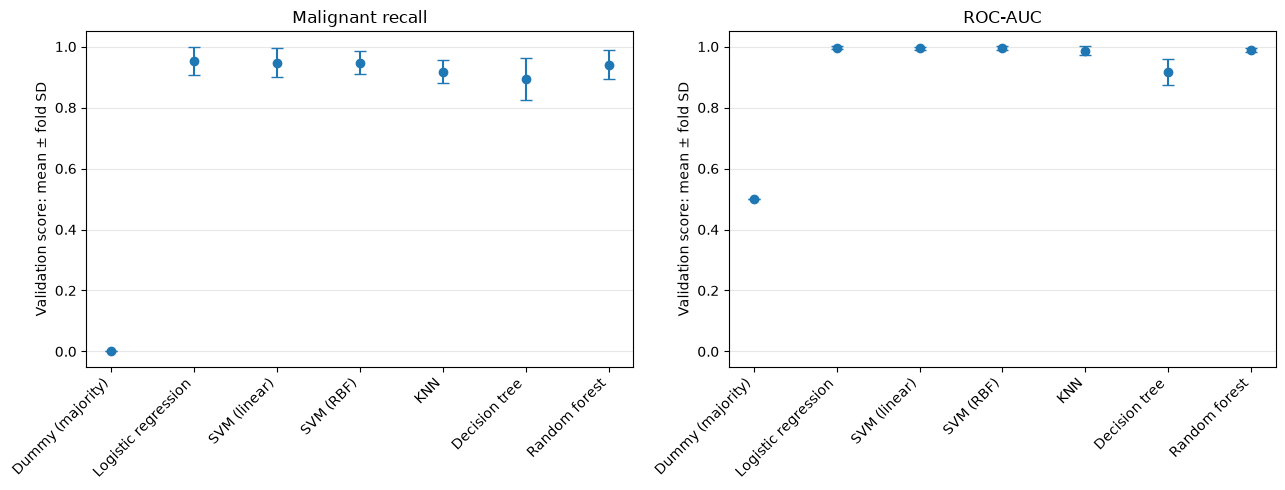

In [169]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
positions = np.arange(len(comparison_summary))

for ax, metric, title in zip(
    axes,
    ["recall", "roc_auc"],
    ["Malignant recall", "ROC-AUC"],
):
    statistics = comparison_summary[metric]

    ax.errorbar(
        positions,
        statistics["mean"],
        yerr=statistics["std"],
        fmt="o",
        capsize=4,
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(
        comparison_summary.index,
        rotation=45,
        ha="right",
    )
    ax.set_title(title)
    ax.set_ylabel("Validation score: mean ± fold SD")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Check completeness, finite scores and consistency with the earlier baseline:

In [170]:
for name, fold_scores in model_fold_scores.items():
    assert fold_scores.shape == (5, len(scoring)), (
        f"Incomplete results for {name}."
    )
    assert np.isfinite(fold_scores.to_numpy()).all(), (
        f"Non-finite scores for {name}."
    )

assert comparison_summary.shape == (
    len(comparison_models),
    2 * len(scoring),
)

assert np.allclose(
    model_fold_scores["Dummy (majority)"],
    baseline_fold_scores,
), "The baseline differs from Task 7; check data and CV settings."

print("Model-comparison verification checks passed.")

Model-comparison verification checks passed.


**Hyperparameter optimisation**

Define compact grids:

In [171]:
from sklearn.model_selection import ParameterGrid

primary_metric = "roc_auc"

param_grids = {
    "Logistic regression": {
        "classifier__C": [0.1, 1.0, 10.0],
    },
    "SVM (linear)": {
        "classifier__C": [0.1, 1.0, 10.0],
    },
    "SVM (RBF)": {
        "classifier__C": [0.1, 1.0, 10.0],
        "classifier__gamma": ["scale", 0.01, 0.1],
    },
    "KNN": {
        "classifier__n_neighbors": [3, 5, 9, 15],
        "classifier__weights": ["uniform", "distance"],
    },
    "Decision tree": {
        "classifier__max_depth": [3, 5, None],
        "classifier__min_samples_leaf": [1, 3, 5],
    },
    "Random forest": {
        "classifier__max_depth": [5, None],
        "classifier__min_samples_leaf": [1, 3, 5],
    },
}

assert set(param_grids) == set(model_pipelines)
assert len(cv_splits) == 5

candidate_counts = pd.Series(
    {
        name: len(ParameterGrid(grid))
        for name, grid in param_grids.items()
    },
    name="parameter_combinations",
)

display(candidate_counts.to_frame())
print("Total CV fits:", candidate_counts.sum() * len(cv_splits))

,parameter_combinations
Logistic regression,3
SVM (linear),3
SVM (RBF),9
KNN,8
Decision tree,9
Random forest,6


Total CV fits: 190


Run one search per pipeline using the same training folds and existing five scoring metrics:

In [172]:
grid_searches = {}
tuning_rows = []

for name, pipeline in model_pipelines.items():
    print(f"Tuning {name}...")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring=scoring,
        refit=primary_metric,
        cv=cv_splits,
        n_jobs=-1,
        error_score="raise",
    )

    search.fit(X_train, y_train)
    grid_searches[name] = search

    best_index = search.best_index_

    row = {
        "model": name,
        "best_parameters": search.best_params_,
    }

    # Extract validation-fold scores for the selected configuration
    for metric in scoring:
        fold_values = np.array([
            search.cv_results_[
                f"split{fold}_test_{metric}"
            ][best_index]
            for fold in range(len(cv_splits))
        ])

        row[f"{metric}_mean"] = fold_values.mean()
        row[f"{metric}_std"] = fold_values.std(ddof=1)

    tuning_rows.append(row)

tuning_summary = pd.DataFrame(tuning_rows).set_index("model")

Tuning Logistic regression...
Tuning SVM (linear)...
Tuning SVM (RBF)...
Tuning KNN...
Tuning Decision tree...
Tuning Random forest...


Display the settings and the primary and secondary performance measures:

In [173]:
print("Best settings within each tested grid:")

for name, search in grid_searches.items():
    print(f"\n{name}:")
    print(search.best_params_)

print("\nCross-validation performance at the selected settings:")

display(
    tuning_summary[
        [
            "roc_auc_mean",
            "roc_auc_std",
            "recall_mean",
            "recall_std",
        ]
    ].round(4)
)

Best settings within each tested grid:

Logistic regression:
{'classifier__C': 1.0}

SVM (linear):
{'classifier__C': 0.1}

SVM (RBF):
{'classifier__C': 10.0, 'classifier__gamma': 0.01}

KNN:
{'classifier__n_neighbors': 15, 'classifier__weights': 'distance'}

Decision tree:
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 5}

Random forest:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1}

Cross-validation performance at the selected settings:


,roc_auc_mean,roc_auc_std,recall_mean,recall_std
model,,,,
Logistic regression,0.9958,0.0052,0.9529,0.0446
SVM (linear),0.9944,0.0068,0.9353,0.0383
SVM (RBF),0.9954,0.0059,0.9529,0.0446
KNN,0.9891,0.0107,0.9059,0.0566
Decision tree,0.9554,0.0302,0.8824,0.0588
Random forest,0.9889,0.0075,0.9412,0.0465


Finally, verify the search results:

In [174]:
assert set(grid_searches) == set(model_pipelines)

for name, search in grid_searches.items():
    # Every candidate should have valid scores for every metric
    for metric in scoring:
        assert np.isfinite(
            search.cv_results_[f"mean_test_{metric}"]
        ).all(), f"Invalid {metric} scores for {name}."

    # Selection must follow the declared primary metric
    assert np.isclose(
        search.best_score_,
        np.max(search.cv_results_["mean_test_roc_auc"]),
    )

    assert np.isclose(
        search.best_score_,
        tuning_summary.loc[name, "roc_auc_mean"],
    )

    # Each grid includes the original Task 8 configuration
    initial_auc = comparison_summary.loc[
        name, ("roc_auc", "mean")
    ]

    assert search.best_score_ >= initial_auc - 1e-12, (
        f"Check the grid, data or CV settings for {name}."
    )

print("Hyperparameter-search verification checks passed.")

Hyperparameter-search verification checks passed.


**Model interpretation**

Examine logistic regression coefficients:

In [175]:
lr_pipeline = grid_searches["Logistic regression"].best_estimator_
lr_classifier = lr_pipeline.named_steps["classifier"]

assert np.array_equal(lr_classifier.classes_, [0, 1])
assert lr_pipeline.named_steps["scaler"].with_std

# Obtain names in the actual order entering the classifier
lr_feature_names = lr_pipeline[:-1].get_feature_names_out()

assert lr_classifier.coef_.shape == (1, len(lr_feature_names))

lr_coefficients = pd.DataFrame(
    {
        "coefficient_per_sd": lr_classifier.coef_[0],
        "odds_ratio_per_sd": np.exp(lr_classifier.coef_[0]),
    },
    index=pd.Index(lr_feature_names, name="feature"),
)

lr_coefficients["absolute_coefficient"] = (
    lr_coefficients["coefficient_per_sd"].abs()
)

lr_coefficients = lr_coefficients.sort_values(
    "absolute_coefficient",
    ascending=False,
)

display(lr_coefficients.head(10).round(3))

,coefficient_per_sd,odds_ratio_per_sd,absolute_coefficient
feature,,,
texture3,1.434,4.196,1.434
radius2,1.233,3.433,1.233
symmetry3,1.061,2.890,1.061
concave_points1,0.953,2.593,0.953
concavity3,0.911,2.488,0.911
area2,0.909,2.482,0.909
compactness2,-0.907,0.404,0.907
area3,0.900,2.461,0.900
radius3,0.897,2.452,0.897


Calculate random forest permutation importance on CV validation folds. Each forest copy is fitted using its fold’s training observations before importance is measured on the validation observations.

In [176]:
from sklearn.base import clone

rf_pipeline = grid_searches["Random forest"].best_estimator_
rf_fold_importances = []

for fold, (fit_positions, valid_positions) in enumerate(
    cv_splits, start=1
):
    print(f"Calculating permutation importance: fold {fold}")

    fold_pipeline = clone(rf_pipeline)

    fold_pipeline.fit(
        X_train.iloc[fit_positions],
        y_train.iloc[fit_positions],
    )

    importance = permutation_importance(
        estimator=fold_pipeline,
        X=X_train.iloc[valid_positions],
        y=y_train.iloc[valid_positions],
        scoring="roc_auc",
        n_repeats=10,
        random_state=42,
        n_jobs=-1,
    )

    rf_fold_importances.append(importance.importances_mean)

rf_fold_importances = pd.DataFrame(
    rf_fold_importances,
    columns=X_train.columns,
    index=pd.RangeIndex(1, len(cv_splits) + 1, name="fold"),
)

rf_importance_table = pd.DataFrame({
    "mean_auc_drop": rf_fold_importances.mean(),
    "std_auc_drop": rf_fold_importances.std(ddof=1),
}).sort_values("mean_auc_drop", ascending=False)

display(rf_importance_table.head(10).round(4))

Calculating permutation importance: fold 1
Calculating permutation importance: fold 2
Calculating permutation importance: fold 3
Calculating permutation importance: fold 4
Calculating permutation importance: fold 5


,mean_auc_drop,std_auc_drop
concave_points3,0.0062,0.0020
area3,0.0059,0.0044
area2,0.0040,0.0051
concave_points1,0.0031,0.0016
perimeter3,0.0028,0.0031
radius3,0.0028,0.0028
compactness2,0.0027,0.0030
concavity1,0.0021,0.0028
perimeter1,0.0021,0.0021
concavity3,0.0018,0.0013


Plot the leading measurements from both methods:

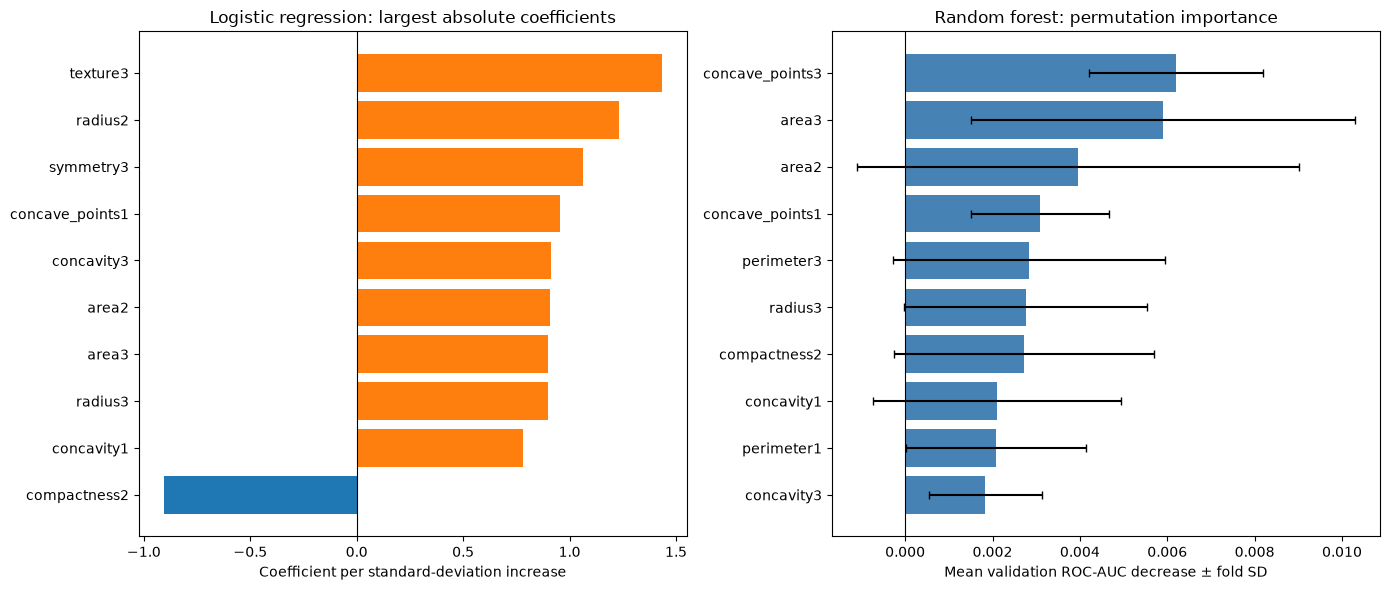

In [177]:
top_lr = lr_coefficients.head(10).sort_values("coefficient_per_sd")
top_rf = rf_importance_table.head(10).sort_values("mean_auc_drop")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(
    top_lr.index,
    top_lr["coefficient_per_sd"],
    color=np.where(
        top_lr["coefficient_per_sd"] >= 0,
        "tab:orange",
        "tab:blue",
    ),
)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Logistic regression: largest absolute coefficients")
axes[0].set_xlabel("Coefficient per standard-deviation increase")

axes[1].barh(
    top_rf.index,
    top_rf["mean_auc_drop"],
    xerr=top_rf["std_auc_drop"],
    capsize=3,
    color="steelblue",
)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Random forest: permutation importance")
axes[1].set_xlabel("Mean validation ROC-AUC decrease ± fold SD")

plt.tight_layout()
plt.show()

To support interpretation of correlated measurements, inspect training-only correlations among the leading features:

In [178]:
discussion_features = lr_coefficients.head(5).index.union(
    rf_importance_table.head(5).index
)

display(
    X_train.loc[:, discussion_features].corr().round(2)
)

,area2,area3,concave_points1,concave_points3,concavity3,perimeter3,radius2,symmetry3,texture3
area2,1.00,0.80,0.69,0.52,0.37,0.75,0.95,0.06,0.18
area3,0.80,1.00,0.82,0.75,0.53,0.98,0.75,0.20,0.35
concave_points1,0.69,0.82,1.00,0.91,0.75,0.86,0.70,0.38,0.30
concave_points3,0.52,0.75,0.91,1.00,0.85,0.82,0.52,0.51,0.36
concavity3,0.37,0.53,0.75,0.85,1.00,0.61,0.37,0.52,0.36
perimeter3,0.75,0.98,0.86,0.82,0.61,1.00,0.72,0.26,0.37
radius2,0.95,0.75,0.70,0.52,0.37,0.72,1.00,0.09,0.18
symmetry3,0.06,0.20,0.38,0.51,0.52,0.26,0.09,1.00,0.24
texture3,0.18,0.35,0.30,0.36,0.36,0.37,0.18,0.24,1.00


Verify feature alignment and valid numerical results:

In [179]:
assert np.array_equal(lr_feature_names, X_train.columns)
assert len(lr_coefficients) == X_train.shape[1]
assert np.isfinite(lr_coefficients.to_numpy()).all()

assert rf_fold_importances.shape == (
    len(cv_splits),
    X_train.shape[1],
)
assert rf_fold_importances.columns.equals(X_train.columns)
assert np.isfinite(rf_importance_table.to_numpy()).all()

print("Model-interpretation checks passed.")

Model-interpretation checks passed.


**Bonus: Feature selection experiment**

First, define the experiment and simple classifier-complexity measures:

In [180]:
from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, f_classif

feature_counts = (30, 10, 5)

# Exploratory limits, specified before inspecting results
max_auc_drop = 0.01
max_recall_drop = 0.02

assert X_train.shape[1] == 30
assert len(cv_splits) == 5


def classifier_complexity(model):
    if isinstance(model, LogisticRegression):
        return "coefficients + intercept", model.coef_.size + model.intercept_.size

    if isinstance(model, SVC):
        return "support vectors", model.n_support_.sum()

    if isinstance(model, KNeighborsClassifier):
        return "stored input values", model.n_samples_fit_ * model.n_features_in_

    if isinstance(model, DecisionTreeClassifier):
        return "tree nodes", model.tree_.node_count

    if isinstance(model, RandomForestClassifier):
        return "total forest nodes", sum(
            tree.tree_.node_count for tree in model.estimators_
        )

    raise TypeError("Unexpected classifier type.")

Next, evaluate all 18 configurations on the existing identical folds. The selector follows any imputation/scaling and precedes the classifier.

In [181]:
fs_cv_results = {}
selected_features = {}
fs_rows = []

for name, template in model_pipelines.items():
    for n_features in feature_counts:
        print(f"Evaluating {name}: {n_features} features")

        base = clone(template)

        experiment_pipeline = Pipeline(
            base.steps[:-1]
            + [
                (
                    "selector",
                    SelectKBest(score_func=f_classif, k=n_features),
                )
            ]
            + [base.steps[-1]]
        )

        results = cross_validate(
            estimator=experiment_pipeline,
            X=X_train,
            y=y_train,
            cv=cv_splits,
            scoring=scoring,
            return_estimator=True,
            error_score="raise",
        )

        key = (name, n_features)
        fs_cv_results[key] = results

        selected_features[key] = [
            fitted[:-1].get_feature_names_out(X_train.columns).tolist()
            for fitted in results["estimator"]
        ]

        classifiers = [
            fitted.named_steps["classifier"]
            for fitted in results["estimator"]
        ]

        complexity_label = classifier_complexity(classifiers[0])[0]
        complexity_values = [
            classifier_complexity(model)[1]
            for model in classifiers
        ]

        row = {
            "model": name,
            "n_features": n_features,
            "input_reduction_pct": 100 * (1 - n_features / 30),
            "complexity_measure": complexity_label,
            "complexity_mean": np.mean(complexity_values),
        }

        for metric in scoring:
            values = results[f"test_{metric}"]
            row[f"{metric}_mean"] = values.mean()
            row[f"{metric}_std"] = values.std(ddof=1)

        # Compare matching validation folds against this model's 30-feature run
        reference = fs_cv_results[(name, 30)]

        row["auc_change_vs_30"] = (
            results["test_roc_auc"] - reference["test_roc_auc"]
        ).mean()

        row["recall_change_vs_30"] = (
            results["test_recall"] - reference["test_recall"]
        ).mean()

        row["small_mean_drop"] = (
            row["auc_change_vs_30"] >= -max_auc_drop
            and row["recall_change_vs_30"] >= -max_recall_drop
        )

        fs_rows.append(row)

fs_summary = pd.DataFrame(fs_rows).set_index(
    ["model", "n_features"]
)

Evaluating Logistic regression: 30 features
Evaluating Logistic regression: 10 features
Evaluating Logistic regression: 5 features
Evaluating SVM (linear): 30 features
Evaluating SVM (linear): 10 features
Evaluating SVM (linear): 5 features
Evaluating SVM (RBF): 30 features
Evaluating SVM (RBF): 10 features
Evaluating SVM (RBF): 5 features
Evaluating KNN: 30 features
Evaluating KNN: 10 features
Evaluating KNN: 5 features
Evaluating Decision tree: 30 features
Evaluating Decision tree: 10 features
Evaluating Decision tree: 5 features
Evaluating Random forest: 30 features
Evaluating Random forest: 10 features
Evaluating Random forest: 5 features


Display performance and complexity separately. Negative changes indicate lower performance than the corresponding 30-feature model.

In [182]:
print("Cross-validation performance:")
display(
    fs_summary[
        [
            "roc_auc_mean",
            "roc_auc_std",
            "recall_mean",
            "recall_std",
            "auc_change_vs_30",
            "recall_change_vs_30",
            "small_mean_drop",
        ]
    ].round(4)
)

print("Classifier complexity:")
display(
    fs_summary[
        [
            "input_reduction_pct",
            "complexity_measure",
            "complexity_mean",
        ]
    ].round(2)
)

Cross-validation performance:


roc_auc_mean  roc_auc_std  recall_mean  \
model               n_features                                           
Logistic regression 30                0.9958       0.0052       0.9529   
                    10                0.9851       0.0134       0.9176   
                    5                 0.9850       0.0126       0.9059   
SVM (linear)        30                0.9942       0.0052       0.9471   
                    10                0.9856       0.0152       0.8941   
                    5                 0.9851       0.0139       0.8647   
SVM (RBF)           30                0.9949       0.0056       0.9471   
                    10                0.9798       0.0141       0.8941   
                    5                 0.9803       0.0143       0.8941   
KNN                 30                0.9871       0.0152       0.9176   
                    10                0.9671       0.0232       0.9118   
                    5                 0.9685       0.0215       0.9118   
Decision tree       30                0.9172       0.0420       0.8941   
                    10                0.9096       0.0289       0.8824   
                    5                 0.9084       0.0162       0.8765   
Random forest       30                0.9889       0.0075       0.9412   
                    10                0.9804       0.0124       0.9235   
                    5                 0.9753       0.0141       0.8941   

                                recall_std  auc_change_vs_30  \
model               n_features                                 
Logistic regression 30              0.0446            0.0000   
                    10              0.0526           -0.0106   
                    5               0.0671           -0.0107   
SVM (linear)        30              0.0483            0.0000   
                    10              0.0610           -0.0087   
                    5               0.0492           -0.0091   
SVM (RBF)           30              0.0383            0.0000   
                    10              0.0644           -0.0152   
                    5               0.0677           -0.0147   
KNN                 30              0.0383            0.0000   
                    10              0.0588           -0.0200   
                    5               0.0690           -0.0186   
Decision tree       30              0.0677            0.0000   
                    10              0.0588           -0.0076   
                    5               0.0383           -0.0088   
Random forest       30              0.0465            0.0000   
                    10              0.0534           -0.0085   
                    5               0.0573           -0.0136   

                                recall_change_vs_30  small_mean_drop  
model               n_features                                        
Logistic regression 30                       0.0000             True  
                    10                      -0.0353            False  
                    5                       -0.0471            False  
SVM (linear)        30                       0.0000             True  
                    10                      -0.0529            False  
                    5                       -0.0824            False  
SVM (RBF)           30                       0.0000             True  
                    10                      -0.0529            False  
                    5                       -0.0529            False  
KNN                 30                       0.0000             True  
                    10                      -0.0059            False  
                    5                       -0.0059            False  
Decision tree       30                       0.0000             True  
                    10                      -0.0118             True  
                    5                       -0.0176             True  
Random forest       30                       0.0000            

Classifier complexity:


input_reduction_pct        complexity_measure  \
model               n_features                                                  
Logistic regression 30                         0.00  coefficients + intercept   
                    10                        66.67  coefficients + intercept   
                    5                         83.33  coefficients + intercept   
SVM (linear)        30                         0.00           support vectors   
                    10                        66.67           support vectors   
                    5                         83.33           support vectors   
SVM (RBF)           30                         0.00           support vectors   
                    10                        66.67           support vectors   
                    5                         83.33           support vectors   
KNN                 30                         0.00       stored input values   
                    10                        66.67       stored input values   
                    5                         83.33       stored input values   
Decision tree       30                         0.00                tree nodes   
                    10                        66.67                tree nodes   
                    5                         83.33                tree nodes   
Random forest       30                         0.00        total forest nodes   
                    10                        66.67        total forest nodes   
                    5                         83.33        total forest nodes   

                                complexity_mean  
model               n_features                   
Logistic regression 30                     31.0  
                    10                     11.0  
                    5                       6.0  
SVM (linear)        30                     30.2  
                    10                     54.0  
                    5                      55.4  
SVM (RBF)           30                     90.4  
                    10                     77.8  
                    5                      68.2  
KNN                 30                  10920.0  
                    10                   3640.0  
                    5                    1820.0  
Decision tree       30                     35.4  
                    10                     42.6  
                    5                      46.2  
Random forest       30                   3066.4  
                    10                   3374.8  
                    5                    3682.8

Plot the primary metric against feature count:

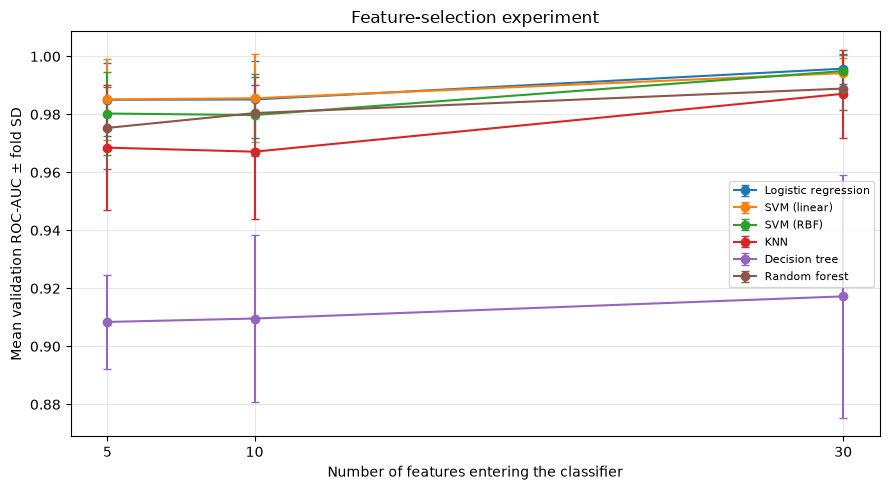

In [183]:
fig, ax = plt.subplots(figsize=(9, 5))

for name in model_pipelines:
    values = fs_summary.loc[name].sort_index()

    ax.errorbar(
        values.index,
        values["roc_auc_mean"],
        yerr=values["roc_auc_std"],
        marker="o",
        capsize=3,
        label=name,
    )

ax.set_xticks([5, 10, 30])
ax.set_xlabel("Number of features entering the classifier")
ax.set_ylabel("Mean validation ROC-AUC ± fold SD")
ax.set_title("Feature-selection experiment")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Finally, verify the selected dimensions, valid scores and reproduction of Task 8’s baseline:

In [184]:
assert len(fs_summary) == len(model_pipelines) * 3

for (name, n_features), results in fs_cv_results.items():
    for metric in scoring:
        assert np.isfinite(results[f"test_{metric}"]).all()

    for fitted in results["estimator"]:
        assert fitted.named_steps["selector"].get_support().sum() == n_features
        assert fitted.named_steps["classifier"].n_features_in_ == n_features

    assert all(
        len(features) == n_features
        for features in selected_features[(name, n_features)]
    )

for name in model_pipelines:
    assert np.isclose(
        fs_summary.loc[(name, 30), "roc_auc_mean"],
        comparison_summary.loc[name, ("roc_auc", "mean")],
    ), f"The 30-feature result differs from Task 8 for {name}."

print("Feature-selection verification checks passed.")

Feature-selection verification checks passed.


**Final held-out test evaluation:**

The selection rule is: highest mean ROC-AUC, then highest malignant recall; remaining ties favour fewer features and lower ROC-AUC variation.

In [185]:
if "final_test_cache" in globals():
    final_selection = final_test_cache["selection"].copy()
    print("Reusing the frozen final selection.")

else:
    candidate_columns = [
        "model", "source", "n_features",
        "roc_auc_mean", "roc_auc_std",
        "recall_mean", "recall_std",
    ]

    tuned_candidates = tuning_summary.reset_index().assign(
        source="tuned",
        n_features=X_train.shape[1],
    )

    feature_candidates = fs_summary.reset_index().assign(
        source="feature_selection",
    )

    selection_table = pd.concat(
        [
            tuned_candidates[candidate_columns],
            feature_candidates[candidate_columns],
        ],
        ignore_index=True,
    ).sort_values(
        [
            "roc_auc_mean", "recall_mean", "n_features",
            "roc_auc_std", "model", "source",
        ],
        ascending=[False, False, True, True, True, False],
    ).reset_index(drop=True)

    selected_spec = selection_table.iloc[0].copy()

    if selected_spec["source"] == "tuned":
        final_template = grid_searches[
            selected_spec["model"]
        ].best_estimator_
    else:
        final_template = fs_cv_results[
            (selected_spec["model"], int(selected_spec["n_features"]))
        ]["estimator"][0]

    # Clone removes previously fitted preprocessing and selection state
    final_pipeline = clone(final_template)
    final_pipeline.fit(X_train, y_train)

    final_selection = selected_spec.to_dict()
    final_selection["decision_rule"] = "Default classifier predict() rule"

    assert np.array_equal(final_pipeline.classes_, [0, 1])
    assert (
        final_pipeline.named_steps["classifier"].n_features_in_
        == int(final_selection["n_features"])
    )

display(pd.Series(final_selection).to_frame("final_selection"))

Reusing the frozen final selection.


,final_selection
model,Logistic regression
source,tuned
n_features,30
roc_auc_mean,0.995769
roc_auc_std,0.005216
recall_mean,0.952941
recall_std,0.044605
decision_rule,Default classifier predict() rule


Next, obtain held-out predictions and continuous scores once each. The cache and guard prevent accidental repeat evaluation in the current kernel.

In [186]:
if "final_test_cache" in globals():
    print("Reusing cached held-out predictions.")

else:
    assert X_test.columns.equals(X_train.columns)
    assert X_test.index.equals(y_test.index)
    assert X_train.index.intersection(X_test.index).empty
    assert set(y_test.unique()) == {0, 1}

    # Create the guard before generating held-out predictions
    final_test_cache = {
        "selection": final_selection.copy(),
        "y_true": y_test.copy(),
    }

    final_test_cache["y_pred"] = final_pipeline.predict(X_test)

    if hasattr(final_pipeline, "decision_function"):
        final_test_cache["y_score"] = final_pipeline.decision_function(X_test)
    else:
        malignant_column = np.flatnonzero(
            final_pipeline.classes_ == 1
        )[0]

        final_test_cache["y_score"] = final_pipeline.predict_proba(
            X_test
        )[:, malignant_column]

# Check that the cache is complete and matches the current test partition
required_keys = {"selection", "y_true", "y_pred", "y_score"}

assert required_keys.issubset(final_test_cache), (
    "The evaluation cache is incomplete; inspect it before proceeding."
)

assert final_test_cache["y_true"].equals(y_test), (
    "The test partition differs from the cached evaluation."
)

Reusing cached held-out predictions.


All remaining cells use cached outputs and can be rerun without evaluating the model again.

In [187]:
test_truth = final_test_cache["y_true"]
test_predictions = final_test_cache["y_pred"]
test_scores = final_test_cache["y_score"]

test_cm = confusion_matrix(
    test_truth,
    test_predictions,
    labels=[0, 1],
)

tn, fp, fn, tp = test_cm.ravel()

final_test_metrics = pd.Series({
    "Malignant sensitivity": recall_score(
        test_truth, test_predictions, pos_label=1, zero_division=0
    ),
    "Specificity": tn / (tn + fp),
    "Malignant precision": precision_score(
        test_truth, test_predictions, pos_label=1, zero_division=0
    ),
    "Malignant F1": f1_score(
        test_truth, test_predictions, pos_label=1, zero_division=0
    ),
    "Accuracy": accuracy_score(test_truth, test_predictions),
    "ROC-AUC": roc_auc_score(test_truth, test_scores),
}, name="held_out_score")

display(final_test_metrics.to_frame().round(4))

print(f"False negatives: {fn} malignant observations predicted benign.")
print(f"False positives: {fp} benign observations predicted malignant.")

,held_out_score
Malignant sensitivity,0.9286
Specificity,0.9861
Malignant precision,0.9750
Malignant F1,0.9512
Accuracy,0.9649
ROC-AUC,0.9960


False negatives: 3 malignant observations predicted benign.
False positives: 1 benign observations predicted malignant.


Generate both figures from the cached predictions:

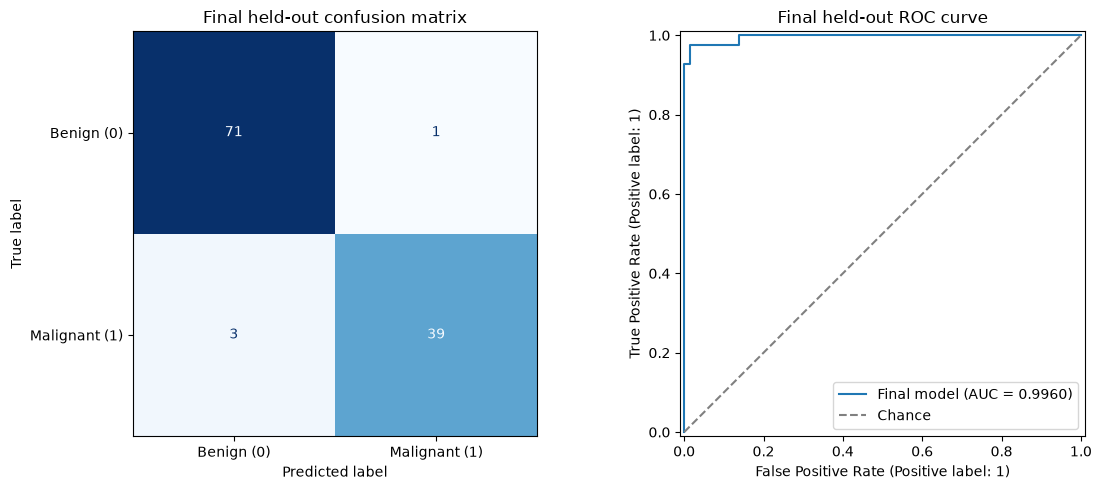

In [188]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Benign (0)", "Malignant (1)"],
).plot(
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    colorbar=False,
)
axes[0].set_title("Final held-out confusion matrix")

RocCurveDisplay.from_predictions(
    test_truth,
    test_scores,
    pos_label=1,
    ax=axes[1],
)
axes[1].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="grey",
    label="Chance",
)
axes[1].set_title("Final held-out ROC curve")
roc_label = f"Final model (AUC = {final_test_metrics['ROC-AUC']:.4f})"
axes[1].legend([roc_label, "Chance"])

plt.tight_layout()
plt.show()

Finally, verify consistency:

In [189]:
assert len(test_predictions) == len(test_scores) == len(test_truth)
assert set(np.unique(test_predictions)).issubset({0, 1})
assert np.isfinite(test_scores).all()

assert test_cm.sum() == len(test_truth)
assert tn + fp == test_truth.eq(0).sum()
assert tp + fn == test_truth.eq(1).sum()

assert final_test_metrics.between(0, 1).all()
assert np.isclose(
    final_test_metrics["Malignant sensitivity"],
    tp / (tp + fn),
)
assert np.isclose(
    final_test_metrics["Specificity"],
    tn / (tn + fp),
)

print("Final evaluation verification checks passed.")

Final evaluation verification checks passed.
